# Vibronic spectra from GW gradients

## What this tutorial is about

Photoemission (UPS), inverse photoemission (IPES) and absorption spectra of
molecules are not sets of sharp lines: when an electron is removed, added or
excited, the nuclei relax, and the spectrum shows a vibrational progression for
every level. This tutorial computes such vibronically resolved spectra with
`pyxtp.vibronic`:

1. optimize the ground state with analytic DFT forces,
2. compute the Hessian by finite differences of these forces,
3. run DFT and GW-BSE **once**, with analytic gradients of a range of
   quasiparticle (QP) levels and of an excited state,
4. turn the gradients into mode-resolved couplings (reorganization energies and
   Huang-Rhys factors),
5. build the spectra (one molecule, then an ensemble) and plot them.

Steps 1-3 are the expensive ones; everything after them takes seconds and can be
repeated as often as needed. As an example we use formaldehyde in a small basis
so that the whole notebook runs in a few minutes. The theory and all options are
described in the manual section *Vibronic spectra*.

In [1]:
import os
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from ase.build import molecule
from ase.optimize import BFGS
from ase.io import write

from pyxtp import xtp
from pyxtp.vibronic import (FiniteDifferenceHessian, xtp_ground_state_factory,
                            QPLevels, level_spectrum, add_gradients,
                            couplings_from_gradient, read_gap_gradient,
                            vibronic_lineshape, Spectrum)
from pyxtp.vibronic.plot import (paper_style, plot_spectrum, plot_couplings,
                                 SINGLE_COLUMN, DOUBLE_COLUMN)

workdir = Path('vibronic').absolute()
workdir.mkdir(exist_ok=True)

## Settings

The same DFT settings must be used in all steps: the Hessian, the gradients and
the geometry belong to one potential energy surface. `settings` uses the
`pyxtp` option names (`calc.set(**settings)`).

In [2]:
settings = {'dftpackage/functional': 'XC_HYB_GGA_XC_PBEH',   # PBE0
            'dftpackage/basisset': 'def2-svp',
            'dftpackage/auxbasisset': 'aux-def2-svp'}
gw_settings = {'gwbse/gw/mode': 'G0W0',
               'gwbse/gw/sigma_integrator': 'ppm',
               'gwbse/bse/exctotal': '5',
               'dftpackage/convergence_tightness': 'verytight'}
nthreads = 2

## Step 1: ground-state geometry

The couplings are computed at the minimum of the ground state, so the geometry
has to be optimized tightly with the same method. `xtp_ground_state_factory`
returns calculators that run only the DFT part of `dftgwbse` with analytic
forces.

In [3]:
factory = xtp_ground_state_factory(settings, nthreads=nthreads)

atoms = molecule('H2CO')
optdir = workdir / 'optimization'
optdir.mkdir(exist_ok=True)
os.chdir(optdir)
atoms.calc = factory(optdir, None)
BFGS(atoms, logfile='bfgs.log').run(fmax=5e-4)
os.chdir(workdir)
atoms.calc = None
write(workdir / 'minimum.xyz', atoms)

## Step 2: Hessian by finite differences

`FiniteDifferenceHessian` displaces every atom along x, y and z in both
directions (6N + 1 = 25 force calculations here). Every displacement runs in its
own directory: a repeated `run()` skips what is done, an interrupted run resumes,
and several processes (or array jobs, `run(part=i, nparts=n)`) can work on the
same directory. The displaced SCFs start from the orbitals of the reference
geometry.

In [4]:
fd = FiniteDifferenceHessian(atoms, factory, workdir=workdir / 'hessian', step=0.005)
print(len(fd.displacements()), 'force calculations')
fd.run()
print(fd.status()['pending'], 'pending')

25 force calculations


[] pending


`normal_modes()` assembles the Hessian and projects out translations and
rotations exactly, so there are always 3N - 6 vibrations. The residual forces at
the reference geometry and the asymmetry of the finite-difference Hessian tell
how reliable the result is.

In [5]:
modes = fd.normal_modes()
modes.save(workdir / 'modes.npz')
print(f'max residual force: {np.abs(fd.reference_forces()).max():.1e} eV/Angstrom')
print(f'Hessian asymmetry:  {fd.asymmetry:.1e} eV/Angstrom^2')
print(modes.summary())

max residual force: 4.1e-04 eV/Angstrom
Hessian asymmetry:  1.9e-03 eV/Angstrom^2
6 vibrational modes, 0 imaginary
  1197.41   1268.25   1532.96   1897.20   2904.18   2969.94


## Step 3: one GW-BSE run with gradients

At the minimum we run DFT and GW-BSE once and ask for analytic gradients of

* the QP energies of a range of levels (`qp_gradients`, here HOMO-3 to LUMO+2),
  for photoemission and inverse photoemission, and
* the lowest singlet excitation (`excited_state='s1'`), for absorption.

Both are stored in the orb file. The gradients include the response of the QP
corrections (G0W0 or evGW, plasmon-pole or exact self-energy).

In [6]:
gwdir = workdir / 'gw'
gwdir.mkdir(exist_ok=True)
os.chdir(gwdir)
calc = xtp(nthreads=nthreads, excited_state='s1')
calc.set(**settings, **gw_settings)
calc.options.qp_gradients = 'homo-3:lumo+2'
gs = atoms.copy()
gs.calc = calc
gs.get_potential_energy()
os.chdir(workdir)
orbfile = gwdir / calc.hdf5_filename
levels = QPLevels.from_orb(orbfile)
for label, e in zip(levels.labels, levels.energies):
    print(f'{label:8s} QP energy {e:9.3f} eV')

HOMO-3   QP energy   -16.469 eV
HOMO-2   QP energy   -15.013 eV
HOMO-1   QP energy   -13.800 eV
HOMO     QP energy    -9.940 eV
LUMO     QP energy     2.738 eV
LUMO+1   QP energy     4.652 eV
LUMO+2   QP energy     6.588 eV


## Step 4: couplings

The gradient of an energy gap, projected on the mass-weighted normal modes, gives
the reorganization energy $\lambda_\nu$ and the Huang-Rhys factor
$S_\nu = \lambda_\nu / \hbar\omega_\nu$ of every mode. For the HOMO, the
oxygen lone pair of formaldehyde, the coupling is weak; the deeper levels and the
LUMO ($\pi^*$) couple strongly to the C=O stretch.

In [7]:
for label, c in zip(levels.labels, levels.couplings(modes)):
    k = np.argmax(c.reorganization)
    print(f'{label:8s} lambda = {c.total_reorganization:.3f} eV, '
          f'strongest mode {c.wavenumbers[k]:.0f} cm^-1 (S = {c.huang_rhys[k]:.2f})')

HOMO-3   lambda = 0.692 eV, strongest mode 1533 cm^-1 (S = 2.14)
HOMO-2   lambda = 0.239 eV, strongest mode 1897 cm^-1 (S = 0.81)
HOMO-1   lambda = 0.573 eV, strongest mode 1897 cm^-1 (S = 2.37)
HOMO     lambda = 0.022 eV, strongest mode 1533 cm^-1 (S = 0.11)
LUMO     lambda = 0.323 eV, strongest mode 1897 cm^-1 (S = 1.10)
LUMO+1   lambda = 0.249 eV, strongest mode 2904 cm^-1 (S = 0.64)
LUMO+2   lambda = 0.186 eV, strongest mode 1897 cm^-1 (S = 0.43)


The excited-state forces of S1 give the couplings of the absorption.
`read_gap_gradient` takes the gradient of the excitation energy from the orb file
(ground-state minus excited-state forces).

lambda = 0.3984 eV, sum S = 1.667, 6 modes
   cm^-1   lambda/meV       S
  1897.2       378.84   1.611
  2904.2        18.84   0.052
  1533.0         0.73   0.004
  2969.9         0.00   0.000


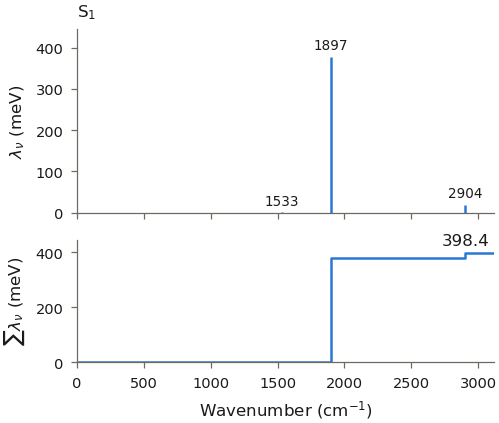

In [8]:
s1 = couplings_from_gradient(modes, read_gap_gradient(orbfile))
print(s1.summary(4))
with paper_style():
    fig = plot_couplings(s1, title='S$_1$')
    plt.show()

## Step 5: spectra of one molecule

`level_spectrum` selects the levels that belong to a process and places the
vibronic line shape of each at its QP energy:

| process | levels | energy axis |
|---|---|---|
| `electron-removal` | occupied | QP energy (HOMO, HOMO-1, ...) |
| `ionization` | occupied | ionization energy, $-E_\mathrm{QP}$ |
| `electron-addition` | empty | QP energy (LUMO, LUMO+1, ...) |
| `electron-affinity` | empty | electron affinity, $-E_\mathrm{QP}$ |

The process also fixes on which side of the 0-0 line the progression lies. A
small Gaussian broadening `sigma` gives every vibronic line a width.

HOMO-3   lambda 0.692 eV, molecular QP energy -16.4685 eV
HOMO-2   lambda 0.239 eV, molecular QP energy -15.0128 eV
HOMO-1   lambda 0.573 eV, molecular QP energy -13.7995 eV
HOMO     lambda 0.022 eV, molecular QP energy -9.9399 eV


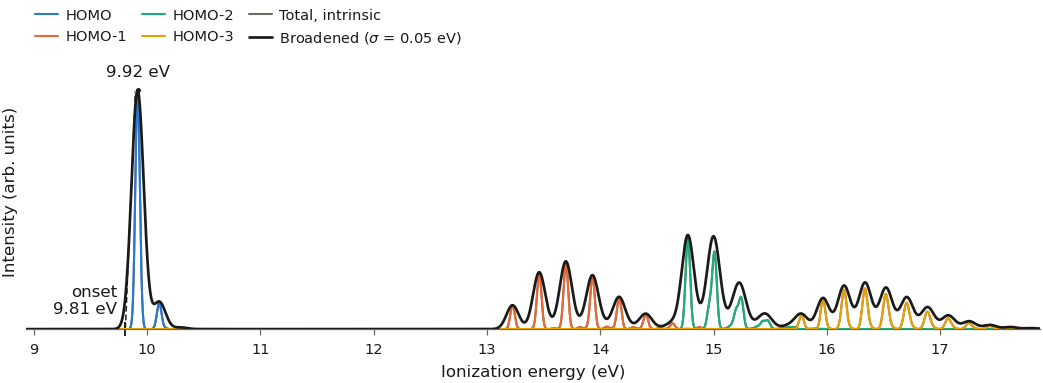

onset 9.81 eV, first peak 9.92 eV


In [9]:
ups = level_spectrum(modes, levels, 'ionization', temperature=300, sigma=0.02)
for label, note in ups.notes.items():
    print(f'{label:8s} lambda {ups.reorganization[label]:.3f} eV, {note}')
with paper_style():
    fig = plot_spectrum(ups, broadening=0.05, onset=True, width=DOUBLE_COLUMN)
    plt.show()
print(f"onset {fig.onset['onset']:.2f} eV, first peak {fig.onset['peak']:.2f} eV")

`broadening` in `plot_spectrum` is an instrument resolution applied on top; the
grey curve is the intrinsic spectrum. The onset is the tangent construction used
for experimental UPS and IPES spectra. The inverse photoemission spectrum of the
empty levels works the same way:

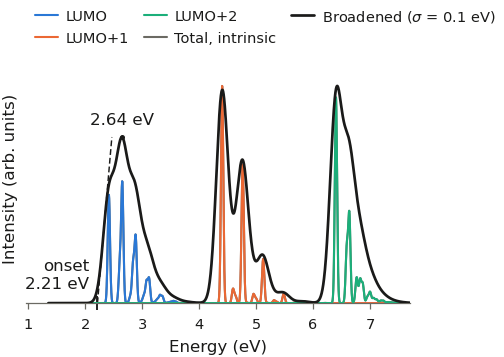

In [10]:
ipes = level_spectrum(modes, levels, 'electron-addition', temperature=300, sigma=0.02)
ipes.save(workdir / 'ipes.dat')
with paper_style():
    fig = plot_spectrum(ipes, broadening=0.1, onset=True)
    plt.show()

The absorption line shape of S1 uses `vibronic_lineshape` directly; it is
relative to the vertical excitation energy, which we take from the BSE run.

vertical 3.654 eV, 0-0 3.256 eV


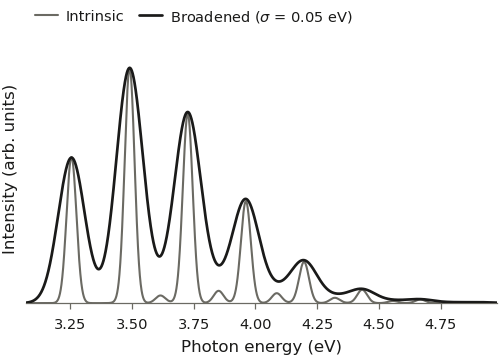

In [11]:
omega_s1 = calc.get_excited_state_total_energy() - calc.get_dft_energy()
shape = vibronic_lineshape(s1, 300, 'absorption', sigma=0.02)
absorption = Spectrum(omega_s1 + shape.energy, {'S$_1$': shape.intensity}, 'absorption',
                      {'S$_1$': shape.reorganization})
print(f'vertical {omega_s1:.3f} eV, 0-0 {omega_s1 + shape.zero_zero:.3f} eV')
with paper_style():
    fig = plot_spectrum(absorption, broadening=0.05)
    plt.show()

## More levels later, without a new GW run

For large molecules DFT and GW are the expensive part. Gradients of further
levels can be added to the existing orb file: `add_gradients` runs `dftgwbse`
with `tasks=gradients`, which reads the file and computes only the levels whose
gradients are not stored yet. The options must be those of the original run
(basis sets and functional are checked).

In [12]:
add_gradients(orbfile, qp_levels='homo-5:lumo+2', settings={**settings, **gw_settings},
              nthreads=nthreads)
levels = QPLevels.from_orb(orbfile)
print(levels.labels)

['HOMO-5', 'HOMO-4', 'HOMO-3', 'HOMO-2', 'HOMO-1', 'HOMO', 'LUMO', 'LUMO+1', 'LUMO+2']


## Ensembles: spectra of a morphology

In a film every molecule has its own vertical energies, e.g. from QM/MM. Such
site energies are passed per level; a level without site energies uses the
distribution of the nearest level that has them, shifted by the difference of
the molecular QP energies (`notes` says how each level was placed). Here we
invent a Gaussian distribution of HOMO ionization energies of 500 sites (0.1 eV
disorder, lowered by 1.2 eV by the polarization of the environment) for
illustration. `select` restricts the spectrum to some levels.

HOMO-3   site energies of HOMO shifted by +6.5287 eV (molecular QP energy difference)
HOMO-2   site energies of HOMO shifted by +5.0730 eV (molecular QP energy difference)
HOMO-1   site energies of HOMO shifted by +3.8596 eV (molecular QP energy difference)
HOMO     500 site energies


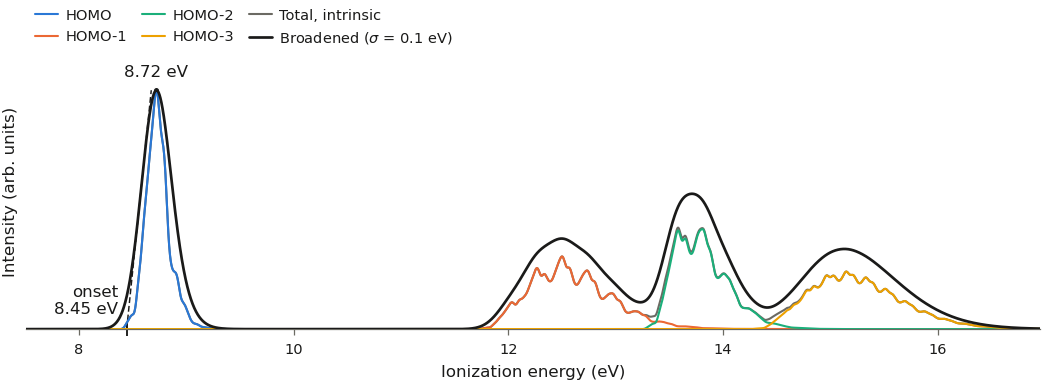

In [13]:
rng = np.random.default_rng(1)
homo_index = levels.homo
e_homo = levels.energies[list(levels.levels).index(homo_index)]
sites = {'homo': -e_homo - 1.2 + 0.1 * rng.standard_normal(500)}   # ionization energies

# only the valence levels (select), the deeper ones lie far out
film = level_spectrum(modes, levels, 'ionization', temperature=300, sigma=0.02,
                      site_energies=sites, select=['homo-3', 'homo-2', 'homo-1', 'homo'])
for label, note in film.notes.items():
    print(f'{label:8s} {note}')
with paper_style():
    fig = plot_spectrum(film, broadening=0.1, onset=True, width=DOUBLE_COLUMN)
    plt.show()

A level keeps its colour in all figures (HOMO and LUMO first, then by the
distance from the gap). To compare with a measurement, pass it as
`experiment=(energies, intensities)`; it is scaled to the maximum of the
broadened total.

## The same on the command line

All steps are also available as the script `xtp_vibronic` (installed together
with `pyxtp`), e.g. for runs on a cluster:

```bash
xtp_vibronic hessian -x minimum.xyz -w hessian -t 4 \
    --set dftpackage.basisset=def2-svp --set dftpackage.auxbasisset=aux-def2-svp
xtp_vibronic hessian -w hessian --part 3 --nparts 16     # e.g. one array job
xtp_vibronic modes -w hessian -m modes.npz
xtp_vibronic gradients molecule.orb --levels homo-9:lumo+9 -o options.xml
xtp_vibronic spectrum -m modes.npz -g molecule.orb -p ionization \
    --sites site_energies.dat --columns homo=2 -o ups.dat
xtp_vibronic plot -s ups.dat --broadening 0.1 --onset -e measured.dat -o ups.pdf
```

`xtp_vibronic <command> --help` lists all options.